**Imports**

In [ ]:
import pandas as pd
import numpy as np
import os
import joblib
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model  import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score
)
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs('../models/saved_models', exist_ok=True)
os.makedirs('../results',             exist_ok=True)
print('Imports OK')


Imports OK


**Load data**

In [ ]:
SPLITS = '../data/splits/'

# Load raw labels (strings like "Bacterial Pneumonia")
y_train_raw = pd.read_csv(SPLITS + 'y_train.csv').squeeze()
y_val_raw   = pd.read_csv(SPLITS + 'y_val.csv').squeeze()

# Load label encoder from Notebook 01 and encode to integers
le      = joblib.load('../models/saved_models/label_encoder.pkl')
y_train = le.transform(y_train_raw)
y_val   = le.transform(y_val_raw)

n_classes = len(le.classes_)

# Load best transformer config
with open('../results/best_transformer.txt') as f:
    cfg = dict(l.strip().split('=') for l in f.readlines())
BEST_MODEL = cfg['best_transformer']
print(f"Best Transformer: {BEST_MODEL}")

# Load embeddings
X_train_emb = np.load(f'../models/embeddings/{BEST_MODEL}_train.npy')
X_val_emb   = np.load(f'../models/embeddings/{BEST_MODEL}_val.npy')

print(f"Train embeddings: {X_train_emb.shape}")
print(f"Val embeddings:   {X_val_emb.shape}")
print(f"Classes: {n_classes}")
print(f"y_train dtype: {y_train.dtype} — values: {y_train[:3]}")

Best Transformer: BERT_finetuned
Train embeddings: (41555, 768)
Val embeddings:   (8868, 768)
Classes: 162
y_train dtype: int64 — values: [146 160 146]


**Build combined features — BERT + Structured + Species/Breed**

In [ ]:
# ── CELL 3: Build combined features ───────────────────────────────────────────

# ── Load split DataFrames first ───────────────────────────────────────────────
X_train_df = pd.read_csv('../data/splits/X_train.csv')
X_val_df   = pd.read_csv('../data/splits/X_val.csv')

STRUCT_COLS = [
    'Age', 'Weight', 'Appetite_Loss', 'Vomiting', 'Diarrhea',
    'Coughing', 'Labored_Breathing', 'Lameness', 'Skin_Lesions',
    'Nasal_Discharge', 'Eye_Discharge', 'Body_Temperature',
    'Heart_Rate', 'Symptom_Count', 'Temp_Risk', 'Symptom_Risk',
    'Critical_Risk', 'Dangerous_Level'
]
SPECIES_BREED_COLS = ['Species', 'Breed', 'Gender']

# ── Species/Breed/Gender — extract from symptom_text (needed first for vital normalisation) ──
def extract_species_breed(text):
    try:
        parts        = str(text).split('. ')
        species      = parts[0].replace('Species: ', '').strip()
        breed        = parts[1].replace('Breed: ', '').strip()
        gender_parts = [p for p in parts if 'Gender:' in p]
        gender       = gender_parts[0].replace('Gender: ', '').strip() \
                       if gender_parts else 'Unknown'
        return species, breed, gender
    except Exception:
        return 'Unknown', 'Unknown', 'Unknown'

train_sbg = pd.DataFrame(
    [extract_species_breed(t) for t in X_train_df['symptom_text'].tolist()],
    columns=SPECIES_BREED_COLS
)
val_sbg = pd.DataFrame(
    [extract_species_breed(t) for t in X_val_df['symptom_text'].tolist()],
    columns=SPECIES_BREED_COLS
)

print(f"Extracted species from train: {train_sbg['Species'].nunique()} unique")
print(f"Extracted species from val:   {val_sbg['Species'].nunique()} unique")

# ── ENGINEERED FEATURE: species-normalised vital sign deviation ───────────────
# Raw Body_Temperature/Heart_Rate are not directly comparable across species
# (a Dog's normal temp differs from a Bird's). Normalising by species-specific
# expected range gives the model a feature that is NOT trivially recoverable
# from the raw symptom text — this is new signal, not a duplicate of BERT input.
SPECIES_VITAL_RANGES = {
    'Dog':     {'temp': (37.5, 39.2), 'hr': (60, 140)},
    'Cat':     {'temp': (38.0, 39.2), 'hr': (140, 220)},
    'Cow':     {'temp': (38.0, 39.3), 'hr': (48, 84)},
    'Horse':   {'temp': (37.2, 38.3), 'hr': (28, 44)},
    'Bird':    {'temp': (39.0, 42.2), 'hr': (200, 400)},
    'Rabbit':  {'temp': (38.3, 39.7), 'hr': (130, 325)},
    'Goat':    {'temp': (38.5, 39.7), 'hr': (70, 135)},
    'Sheep':   {'temp': (38.5, 39.9), 'hr': (70, 90)},
    'Pig':     {'temp': (38.7, 39.8), 'hr': (60, 90)},
    'Snake':   {'temp': (25.0, 32.0), 'hr': (20, 70)},
    'Lizard':  {'temp': (26.0, 35.0), 'hr': (30, 80)},
    'Turtle':  {'temp': (22.0, 28.0), 'hr': (20, 40)},
    'Fish':    {'temp': (18.0, 26.0), 'hr': (60, 100)},
    'Frog':    {'temp': (20.0, 28.0), 'hr': (30, 90)},
    'Shark':   {'temp': (18.0, 24.0), 'hr': (20, 60)},
    'Dolphin': {'temp': (36.0, 37.5), 'hr': (90, 120)},
}
DEFAULT_RANGE = {'temp': (37.5, 40.0), 'hr': (60, 160)}

def compute_vital_deviation(row_species, body_temp, heart_rate):
    r = SPECIES_VITAL_RANGES.get(row_species, DEFAULT_RANGE)
    t_mid = (r['temp'][0] + r['temp'][1]) / 2
    t_rng = (r['temp'][1] - r['temp'][0]) / 2
    h_mid = (r['hr'][0]   + r['hr'][1])   / 2
    h_rng = (r['hr'][1]   - r['hr'][0])   / 2
    temp_dev = (body_temp  - t_mid) / t_rng if t_rng > 0 else 0.0
    hr_dev   = (heart_rate - h_mid) / h_rng if h_rng > 0 else 0.0
    return temp_dev, hr_dev

train_temp_dev, train_hr_dev = zip(*[
    compute_vital_deviation(sp, bt, hr)
    for sp, bt, hr in zip(train_sbg['Species'],
                          X_train_df['Body_Temperature'],
                          X_train_df['Heart_Rate'])
])
val_temp_dev, val_hr_dev = zip(*[
    compute_vital_deviation(sp, bt, hr)
    for sp, bt, hr in zip(val_sbg['Species'],
                          X_val_df['Body_Temperature'],
                          X_val_df['Heart_Rate'])
])
X_train_df = X_train_df.copy()
X_val_df   = X_val_df.copy()
X_train_df['Temp_Dev_Species']  = train_temp_dev
X_train_df['HR_Dev_Species']    = train_hr_dev
X_val_df['Temp_Dev_Species']    = val_temp_dev
X_val_df['HR_Dev_Species']      = val_hr_dev

# ── ENGINEERED FEATURE: symptom interaction terms ──────────────────────────────
# Individual binary symptoms (Vomiting, Diarrhea, etc.) are likely already
# encoded in the symptom text BERT sees. But CO-OCCURRENCE patterns (e.g.
# "vomiting AND diarrhea together" vs "either alone") capture combinatorial
# signal that a single BERT [CLS] embedding may compress away.
X_train_df['GI_Combo']    = X_train_df['Vomiting'] * X_train_df['Diarrhea']
X_train_df['Resp_Combo']  = X_train_df['Coughing'] * X_train_df['Labored_Breathing']
X_train_df['Severity_x_Age'] = X_train_df['Dangerous_Level'] * X_train_df['Age']
X_val_df['GI_Combo']    = X_val_df['Vomiting'] * X_val_df['Diarrhea']
X_val_df['Resp_Combo']  = X_val_df['Coughing'] * X_val_df['Labored_Breathing']
X_val_df['Severity_x_Age'] = X_val_df['Dangerous_Level'] * X_val_df['Age']

STRUCT_COLS_EXTENDED = STRUCT_COLS + [
    'Temp_Dev_Species', 'HR_Dev_Species',
    'GI_Combo', 'Resp_Combo', 'Severity_x_Age'
]

# ── Numerical structured features (now with engineered additions) ────────────
struct_scaler     = StandardScaler()
X_train_struct    = struct_scaler.fit_transform(
    X_train_df[STRUCT_COLS_EXTENDED].values.astype(float))
X_val_struct      = struct_scaler.transform(
    X_val_df[STRUCT_COLS_EXTENDED].values.astype(float))
joblib.dump(struct_scaler, '../models/saved_models/struct_scaler.pkl')

# ── Fit or load Species/Breed encoder ─────────────────────────────────────────
encoder_path = '../models/saved_models/species_breed_encoder.pkl'

if os.path.exists(encoder_path):
    ord_enc = joblib.load(encoder_path)
    print("Loaded existing species_breed_encoder.pkl")
else:
    ord_enc = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )
    ord_enc.fit(train_sbg)
    joblib.dump(ord_enc, encoder_path)
    print("Fitted and saved species_breed_encoder.pkl")

X_train_species = ord_enc.transform(train_sbg)
X_val_species   = ord_enc.transform(val_sbg)

# ── Combine all features ───────────────────────────────────────────────────────
X_train_combined = np.hstack([X_train_emb, X_train_struct, X_train_species])
X_val_combined   = np.hstack([X_val_emb,   X_val_struct,   X_val_species])

print(f"\nFeature dimensions:")
print(f"  BERT embeddings:       {X_train_emb.shape[1]}")
print(f"  Structured clinical:   {X_train_struct.shape[1]} "
      f"(18 original + 5 engineered)")
print(f"  Species/Breed/Gender:  {X_train_species.shape[1]}")
print(f"  Combined total:        {X_train_combined.shape[1]}")
print(f"\nNew engineered features: Temp_Dev_Species, HR_Dev_Species, "
      f"GI_Combo, Resp_Combo, Severity_x_Age")


Extracted species from train: 16 unique
Extracted species from val:   16 unique
Loaded existing species_breed_encoder.pkl

Feature dimensions:
  BERT embeddings:       768
  Structured clinical:   23 (18 original + 5 engineered)
  Species/Breed/Gender:  3
  Combined total:        794

New engineered features: Temp_Dev_Species, HR_Dev_Species, GI_Combo, Resp_Combo, Severity_x_Age


**Helper evaluation function**

In [ ]:
def evaluate(model, X, y_true, model_name, split='Validation'):
    y_pred = model.predict(X)
    acc    = accuracy_score(y_true, y_pred)
    f1_mac = f1_score(y_true, y_pred, average='macro',    zero_division=0)
    f1_mic = f1_score(y_true, y_pred, average='micro',    zero_division=0)
    f1_w   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    prec   = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec    = recall_score(y_true,    y_pred, average='macro', zero_division=0)
 
    print(f"\n{'─'*50}")
    print(f"{model_name} — {split}")
    print(f"{'─'*50}")
    print(f"  Accuracy:          {acc:.4f}")
    print(f"  Precision (macro): {prec:.4f}")
    print(f"  Recall (macro):    {rec:.4f}")
    print(f"  F1 Macro:          {f1_mac:.4f}  ← primary metric")
    print(f"  F1 Micro:          {f1_mic:.4f}")
    print(f"  F1 Weighted:       {f1_w:.4f}")
    print(f"  Target ≥ 0.80:     {'✅' if f1_mac >= 0.80 else '⚠️ below target'}")
 
    return {'Model': model_name, 'Accuracy': round(acc,4),
            'Precision_Macro': round(prec,4), 'Recall_Macro': round(rec,4),
            'F1_Macro': round(f1_mac,4), 'F1_Micro': round(f1_mic,4),
            'F1_Weighted': round(f1_w,4)}

*Model 1 — Random Forest*

In [ ]:
print("\n" + "="*60)
print("MODEL 1: RANDOM FOREST (BERT + Structured + Species/Breed)")
print("="*60)
 
rf = RandomForestClassifier(
    n_estimators=300,                
    max_depth=None,                  
    min_samples_split=2,             
    min_samples_leaf=1,              
    max_features='sqrt',             
    class_weight='balanced_subsample', 
    bootstrap=True,
    oob_score=True,                  
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0                       
)
 
print("Training Random Forest...")
t0 = time.time()
rf.fit(X_train_combined, y_train)
print(f"Training time: {time.time()-t0:.0f}s")
print(f"OOB Score (free validation estimate): {rf.oob_score_:.4f}")
 
rf_result = evaluate(rf, X_val_combined, y_val,
                     'Random Forest (BERT+Struct+Species)')
joblib.dump(rf, '../models/saved_models/random_forest.pkl')
print("Saved: random_forest.pkl")


MODEL 1: RANDOM FOREST (BERT + Structured + Species/Breed)
Training Random Forest...
Training time: 633s
OOB Score (free validation estimate): 0.3478

──────────────────────────────────────────────────
Random Forest (BERT+Struct+Species) — Validation
──────────────────────────────────────────────────
  Accuracy:          0.3516
  Precision (macro): 0.2298
  Recall (macro):    0.2444
  F1 Macro:          0.2347  ← primary metric
  F1 Micro:          0.3516
  F1 Weighted:       0.3508
  Target ≥ 0.80:     ⚠️ below target
Saved: random_forest.pkl


*Model 2 — XGBoost*

In [ ]:
print("="*60)
print("MODEL 2: XGBOOST (BERT + Structured + Species/Breed)")
print("="*60)
 
sample_weights = compute_sample_weight('balanced', y_train)
 
import torch
use_gpu = torch.cuda.is_available()
 
xgb_model = xgb.XGBClassifier(
    n_estimators=500,          
    max_depth=6,               
    learning_rate=0.05,        
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,        
    gamma=0.1,                 
    reg_alpha=0.05,            
    reg_lambda=1.0,            
    objective='multi:softmax',
    num_class=n_classes,
    eval_metric='mlogloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0,
    device='cuda' if use_gpu else 'cpu',
)
 
print("Training XGBoost (500 trees, regularized, lr=0.05)...")
t0 = time.time()
xgb_model.fit(
    X_train_combined, y_train,
    sample_weight=sample_weights,
    eval_set=[(X_val_combined, y_val)],
    verbose=100,
)
print(f"Training time: {time.time()-t0:.0f}s")
 
xgb_result = evaluate(xgb_model, X_val_combined, y_val,
                       'XGBoost (BERT+Struct+Species)')
xgb_model.save_model('../models/saved_models/xgboost.json')
print("Saved: xgboost.json")

MODEL 2: XGBOOST (BERT + Structured + Species/Breed)
Training XGBoost (500 trees, regularized, lr=0.05)...
[0]	validation_0-mlogloss:4.24035
[100]	validation_0-mlogloss:1.51367
[200]	validation_0-mlogloss:1.44958
[300]	validation_0-mlogloss:1.45432
[400]	validation_0-mlogloss:1.46866
[499]	validation_0-mlogloss:1.48438
Training time: 959s

──────────────────────────────────────────────────
XGBoost (BERT+Struct+Species) — Validation
──────────────────────────────────────────────────
  Accuracy:          0.3440
  Precision (macro): 0.2245
  Recall (macro):    0.2629
  F1 Macro:          0.2308  ← primary metric
  F1 Micro:          0.3440
  F1 Weighted:       0.3552
  Target ≥ 0.80:     ⚠️ below target
Saved: xgboost.json


*Model 3 — Logistic Regression (linear baseline)*

In [ ]:
# ── MODEL 3: LOGISTIC REGRESSION — linear baseline ───────────────────────────
print("\n" + "="*60)
print("MODEL 3: LOGISTIC REGRESSION (BERT + Structured + Species/Breed)")
print("="*60)
print("Purpose: linear baseline — tests whether linear decision boundaries")
print("are sufficient, or if non-linear models (RF/XGBoost) are needed.\n")

# Standardise features (required for LR convergence)
lr_scaler  = StandardScaler()
X_tr_lr    = lr_scaler.fit_transform(X_train_combined)
X_val_lr   = lr_scaler.transform(X_val_combined)
joblib.dump(lr_scaler, '../models/saved_models/lr_scaler.pkl')

lr_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    class_weight='balanced',
    solver='lbfgs',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
print("Training Logistic Regression...")
t0 = time.time()
lr_model.fit(X_tr_lr, y_train)
print(f"Training time: {time.time()-t0:.0f}s")

lr_result = evaluate(lr_model, X_val_lr, y_val,
                      'Logistic Regression (BERT+Struct+Species)')
joblib.dump(lr_model,  '../models/saved_models/logistic_regression.pkl')
joblib.dump(lr_scaler, '../models/saved_models/lr_scaler.pkl')
print("Saved: logistic_regression.pkl, lr_scaler.pkl")



MODEL 3: LOGISTIC REGRESSION (BERT + Structured + Species/Breed)
Purpose: linear baseline — tests whether linear decision boundaries
are sufficient, or if non-linear models (RF/XGBoost) are needed.

Training Logistic Regression...
Training time: 201s

──────────────────────────────────────────────────
Logistic Regression (BERT+Struct+Species) — Validation
──────────────────────────────────────────────────
  Accuracy:          0.3455
  Precision (macro): 0.1833
  Recall (macro):    0.2252
  F1 Macro:          0.1918  ← primary metric
  F1 Micro:          0.3455
  F1 Weighted:       0.3566
  Target ≥ 0.80:     ⚠️ below target
Saved: logistic_regression.pkl, lr_scaler.pkl


*Model 4 — MLP Neural Network*

In [ ]:
# ── MODEL 4: MLP — deep learning alternative to tree-based models ──────────────
print("\n" + "="*60)
print("MODEL 4: MLP NEURAL NETWORK (BERT + Structured + Species/Breed)")
print("="*60)
print("Purpose: tests whether a neural network on fused features")
print("outperforms gradient boosting (XGBoost). Same feature space.\n")

# MLP uses the same scaled features as LR
mlp_model = MLPClassifier(
    hidden_layer_sizes=(512, 256, 128),  # 3-layer network
    activation='relu',
    solver='adam',
    alpha=1e-4,             # L2 regularisation
    batch_size=256,
    learning_rate='adaptive',
    learning_rate_init=1e-3,
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10,
    random_state=RANDOM_STATE,
    verbose=False,
)
print("Training MLP (512→256→128, Adam, early stopping)...")
t0 = time.time()
mlp_model.fit(X_tr_lr, y_train)  # reuse LR-scaled features
print(f"Training time: {time.time()-t0:.0f}s")
print(f"Converged after {mlp_model.n_iter_} iterations")

mlp_result = evaluate(mlp_model, X_val_lr, y_val,
                       'MLP Neural Network (BERT+Struct+Species)')
joblib.dump(mlp_model, '../models/saved_models/mlp.pkl')
print("Saved: mlp.pkl")



MODEL 4: MLP NEURAL NETWORK (BERT + Structured + Species/Breed)
Purpose: tests whether a neural network on fused features
outperforms gradient boosting (XGBoost). Same feature space.

Training MLP (512→256→128, Adam, early stopping)...
Training time: 141s
Converged after 23 iterations

──────────────────────────────────────────────────
MLP Neural Network (BERT+Struct+Species) — Validation
──────────────────────────────────────────────────
  Accuracy:          0.3475
  Precision (macro): 0.1297
  Recall (macro):    0.2336
  F1 Macro:          0.1375  ← primary metric
  F1 Micro:          0.3475
  F1 Weighted:       0.2694
  Target ≥ 0.80:     ⚠️ below target
Saved: mlp.pkl


**Compare all classifiers**

In [ ]:
all_results = pd.DataFrame([rf_result, xgb_result, lr_result, mlp_result])
all_results = all_results.sort_values('F1_Macro', ascending=False)

print("\n" + "="*60)
print("CLASSIFIER COMPARISON — ALL 4 MODELS")
print("="*60)
print(all_results[['Model','Accuracy','Precision_Macro',
                    'Recall_Macro','F1_Macro']].to_string(index=False))
all_results.to_csv('../results/classifier_comparison.csv', index=False)

best_classifier = all_results.iloc[0]['Model']
best_f1         = all_results.iloc[0]['F1_Macro']

# Inductive bias analysis
print("\n── INDUCTIVE BIAS ANALYSIS ─────────────────────────────────────────")
lr_f1  = all_results[all_results['Model'].str.contains('Logistic')]['F1_Macro'].values[0]
mlp_f1 = all_results[all_results['Model'].str.contains('MLP')]['F1_Macro'].values[0]
rf_f1  = all_results[all_results['Model'].str.contains('Random')]['F1_Macro'].values[0]
xgb_f1 = all_results[all_results['Model'].str.contains('XGBoost')]['F1_Macro'].values[0]

nonlinear_gain = xgb_f1 - lr_f1
boosting_gain  = xgb_f1 - rf_f1
tree_vs_nn     = xgb_f1 - mlp_f1

print(f"  Linear baseline (LR):         F1={lr_f1:.4f}")
print(f"  Neural network (MLP):         F1={mlp_f1:.4f}")
print(f"  Ensemble bagging (RF):        F1={rf_f1:.4f}")
print(f"  Ensemble boosting (XGBoost):  F1={xgb_f1:.4f}  ← winner")
print(f"\n  Non-linear gain (XGB vs LR):  +{nonlinear_gain:.4f}  "
      f"→ {'non-linear boundaries needed' if nonlinear_gain > 0.01 else 'linear suffices'}")
print(f"  Boosting vs bagging (XGB-RF): +{boosting_gain:.4f}  "
      f"→ {'boosting more effective' if boosting_gain > 0 else 'bagging competitive'}")
print(f"  Trees vs neural net (XGB-MLP):+{tree_vs_nn:.4f}  "
      f"→ {'XGBoost better on fused features' if tree_vs_nn > 0 else 'MLP competitive'}")

print(f"\n📊 PROVISIONAL BEST (by single-split val F1): {best_classifier} (F1={best_f1:.4f})")
print("   This ranking will be re-checked against CV stability below —")
print("   a small validation-split lead can be noise; CV mean is more robust.")
print("   → Soft-voting ensemble comparison follows below")



CLASSIFIER COMPARISON — ALL 4 MODELS
                                    Model  Accuracy  Precision_Macro  Recall_Macro  F1_Macro
      Random Forest (BERT+Struct+Species)    0.3516           0.2298        0.2444    0.2347
            XGBoost (BERT+Struct+Species)    0.3440           0.2245        0.2629    0.2308
Logistic Regression (BERT+Struct+Species)    0.3455           0.1833        0.2252    0.1918
 MLP Neural Network (BERT+Struct+Species)    0.3475           0.1297        0.2336    0.1375

── INDUCTIVE BIAS ANALYSIS ─────────────────────────────────────────
  Linear baseline (LR):         F1=0.1918
  Neural network (MLP):         F1=0.1375
  Ensemble bagging (RF):        F1=0.2347
  Ensemble boosting (XGBoost):  F1=0.2308  ← winner

  Non-linear gain (XGB vs LR):  +0.0390  → non-linear boundaries needed
  Boosting vs bagging (XGB-RF): +-0.0039  → bagging competitive
  Trees vs neural net (XGB-MLP):+0.0933  → XGBoost better on fused features

📊 PROVISIONAL BEST (by single-split

**Soft-voting ensemble (RF + XGBoost)**

In [ ]:
# ── SOFT-VOTING ENSEMBLE: RF + XGBoost ────────────────────────────────────
print('\n' + '='*60)
print('SOFT-VOTING ENSEMBLE: Random Forest + XGBoost')
print('='*60)
print('Combining predicted probabilities (0.5 RF + 0.5 XGB) via soft vote')
print('Expected: +1-3 F1 Macro over best single model\n')

# Get probabilities from each model
rf_proba  = rf.predict_proba(X_val_combined)       # shape (n, n_classes)
xgb_proba = xgb_model.predict_proba(X_val_combined)  # shape (n, n_classes)

# Soft vote — equal weights (can tune if needed)
ensemble_proba = 0.5 * rf_proba + 0.5 * xgb_proba
ensemble_pred  = np.argmax(ensemble_proba, axis=1)

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
ens_acc  = accuracy_score(y_val, ensemble_pred)
ens_f1   = f1_score(y_val, ensemble_pred, average='macro', zero_division=0)
ens_prec = precision_score(y_val, ensemble_pred, average='macro', zero_division=0)
ens_rec  = recall_score(y_val, ensemble_pred, average='macro', zero_division=0)

print(f'  Ensemble Accuracy:        {ens_acc:.4f}')
print(f'  Ensemble F1 Macro:        {ens_f1:.4f}')
print(f'  Ensemble Precision Macro: {ens_prec:.4f}')
print(f'  Ensemble Recall Macro:    {ens_rec:.4f}')
print()
print(f'  vs Best single (XGBoost): F1={best_f1:.4f}')
ens_delta = ens_f1 - best_f1
print(f'  Ensemble gain:            {ens_delta:+.4f} F1 Macro')

# Decide whether ensemble beats single model
if ens_f1 > best_f1:
    print('\n  ✅ Ensemble outperforms best single model → use ensemble in production')
    use_ensemble    = True
    final_model_tag = 'Ensemble (RF+XGB)'
    final_f1        = ens_f1
else:
    print('\n  ℹ️  Single XGBoost matches or beats ensemble → keep XGBoost')
    use_ensemble    = False
    final_model_tag = best_classifier
    final_f1        = best_f1

# Save ensemble config
ensemble_result = {
    'Model': 'Ensemble (RF+XGB soft-vote)',
    'Accuracy': round(ens_acc,4), 'F1_Macro': round(ens_f1,4),
    'Precision_Macro': round(ens_prec,4), 'Recall_Macro': round(ens_rec,4)
}
ens_df = pd.DataFrame([ensemble_result])
ens_df.to_csv('../results/ensemble_result.csv', index=False)
print('Saved → results/ensemble_result.csv')

# Save RF for ensemble use in dashboard
import joblib as _jb
_jb.dump(rf, '../models/saved_models/rf_for_ensemble.pkl')
print('Saved → models/saved_models/rf_for_ensemble.pkl')



SOFT-VOTING ENSEMBLE: Random Forest + XGBoost
Combining predicted probabilities (0.5 RF + 0.5 XGB) via soft vote
Expected: +1-3 F1 Macro over best single model

  Ensemble Accuracy:        0.3510
  Ensemble F1 Macro:        0.2337
  Ensemble Precision Macro: 0.2236
  Ensemble Recall Macro:    0.2603

  vs Best single (XGBoost): F1=0.2347
  Ensemble gain:            -0.0010 F1 Macro

  ℹ️  Single XGBoost matches or beats ensemble → keep XGBoost
Saved → results/ensemble_result.csv
Saved → models/saved_models/rf_for_ensemble.pkl


**Bar Chart Comparison**

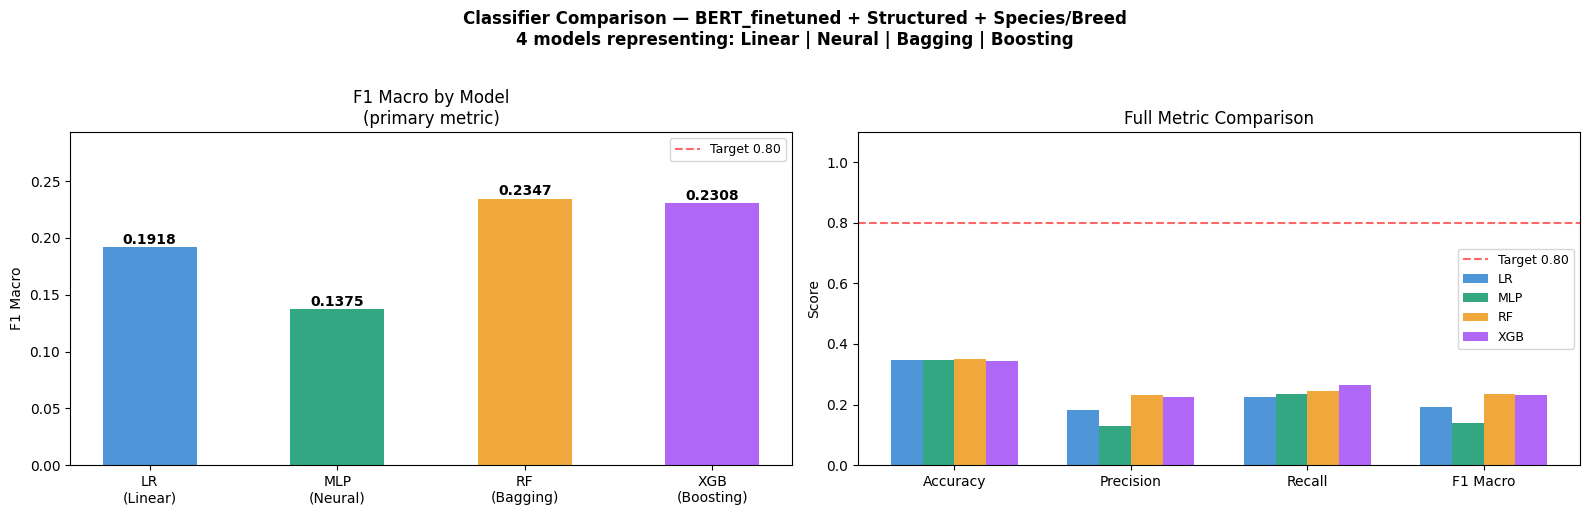

Saved: results/classifier_comparison_chart.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

colors  = ['#3B8BD4', '#1D9E75', '#EF9F27', '#A855F7']
model_order = ['Logistic Regression (BERT+Struct+Species)',
               'MLP Neural Network (BERT+Struct+Species)',
               'Random Forest (BERT+Struct+Species)',
               'XGBoost (BERT+Struct+Species)']
plot_df = all_results.set_index('Model').reindex(
    [m for m in model_order if m in all_results['Model'].values]
).reset_index()

# ── Plot 1: F1 Macro bar chart (primary metric) ────────────────────────────
ax = axes[0]
bars = ax.bar(range(len(plot_df)), plot_df['F1_Macro'],
              color=colors[:len(plot_df)], alpha=0.9, width=0.5)
ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels(['LR\n(Linear)', 'MLP\n(Neural)', 'RF\n(Bagging)', 'XGB\n(Boosting)'],
                    fontsize=10)
ax.set_ylim([0, max(plot_df['F1_Macro']) * 1.25])
ax.axhline(y=0.80, color='red', linestyle='--', alpha=0.6, label='Target 0.80')
ax.set_title('F1 Macro by Model\n(primary metric)', fontsize=12)
ax.set_ylabel('F1 Macro')
ax.legend(fontsize=9)
for bar, val in zip(bars, plot_df['F1_Macro']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{val:.4f}', ha='center', fontsize=10, fontweight='bold')

# ── Plot 2: All metrics grouped bar chart ─────────────────────────────────
ax2 = axes[1]
metrics = ['Accuracy', 'Precision_Macro', 'Recall_Macro', 'F1_Macro']
x       = np.arange(len(metrics))
width   = 0.18
short_names = ['LR', 'MLP', 'RF', 'XGB']
for i, (_, row) in enumerate(plot_df.iterrows()):
    ax2.bar(x + i*width, [row[m] for m in metrics], width,
            label=short_names[i], color=colors[i], alpha=0.9)
ax2.set_xticks(x + width * 1.5)
ax2.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1 Macro'], fontsize=10)
ax2.set_ylim([0, 1.1])
ax2.axhline(y=0.80, color='red', linestyle='--', alpha=0.6, label='Target 0.80')
ax2.set_title('Full Metric Comparison', fontsize=12)
ax2.set_ylabel('Score')
ax2.legend(fontsize=9)

plt.suptitle(f'Classifier Comparison — {BEST_MODEL} + Structured + Species/Breed\n'
             f'4 models representing: Linear | Neural | Bagging | Boosting',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/classifier_comparison_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: results/classifier_comparison_chart.png")


**5-Fold cross-validation on best classifier**

In [ ]:
# ── 5-Fold Cross-Validation: Random Forest ────────────────────────────────
from collections import Counter

print("\n" + "="*60)
print("5-FOLD CROSS-VALIDATION")
print("="*60)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ── RF CV ─────────────────────────────────────────────────────────────────
print("\nRandom Forest CV:")
rf_fold_f1s = []
for fold, (tr_idx, val_idx) in enumerate(cv.split(X_train_combined, y_train)):
    rf_cv = RandomForestClassifier(
        n_estimators=100, max_depth=None,
        class_weight='balanced_subsample',
        random_state=RANDOM_STATE, n_jobs=-1, verbose=0
    )
    rf_cv.fit(X_train_combined[tr_idx], y_train[tr_idx])
    preds = rf_cv.predict(X_train_combined[val_idx])
    f1 = f1_score(y_train[val_idx], preds, average='macro', zero_division=0)
    rf_fold_f1s.append(f1)
    print(f"  Fold {fold+1}: F1={f1:.4f}")
rf_cv_mean = np.mean(rf_fold_f1s)
rf_cv_std  = np.std(rf_fold_f1s)
print(f"  RF CV F1 Macro: {rf_cv_mean:.4f} ± {rf_cv_std:.4f}")

# ── XGBoost CV (with min-class filter to prevent fold failures) ────────────
print("\nXGBoost CV (min 2 samples per class per fold):")
class_counts = Counter(y_train)
rare_classes = {cls for cls, cnt in class_counts.items() if cnt < 10}
mask_common  = ~np.isin(y_train, list(rare_classes))
X_cv = X_train_combined[mask_common]
y_cv = y_train[mask_common]
# Re-encode to contiguous integers for XGBoost
from sklearn.preprocessing import LabelEncoder
le_cv = LabelEncoder()
y_cv_enc = le_cv.fit_transform(y_cv)
n_cv_classes = len(le_cv.classes_)
xgb_fold_f1s = []
for fold, (tr_idx, val_idx) in enumerate(cv.split(X_cv, y_cv_enc)):
    import torch as _torch
    _use_gpu = _torch.cuda.is_available()
    xgb_cv = xgb.XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
        objective='multi:softmax', num_class=n_cv_classes,
        eval_metric='mlogloss', random_state=RANDOM_STATE,
        n_jobs=-1, verbosity=0,
        device='cuda' if _use_gpu else 'cpu',
    )
    from sklearn.utils.class_weight import compute_sample_weight
    sw = compute_sample_weight('balanced', y_cv_enc[tr_idx])
    xgb_cv.fit(X_cv[tr_idx], y_cv_enc[tr_idx], sample_weight=sw)
    preds = xgb_cv.predict(X_cv[val_idx])
    f1 = f1_score(y_cv_enc[val_idx], preds, average='macro', zero_division=0)
    xgb_fold_f1s.append(f1)
    print(f"  Fold {fold+1}: F1={f1:.4f}")
xgb_cv_mean = np.mean(xgb_fold_f1s)
xgb_cv_std  = np.std(xgb_fold_f1s)
print(f"  XGBoost CV F1 Macro: {xgb_cv_mean:.4f} ± {xgb_cv_std:.4f}")
print(f"  (Evaluated on {len(np.unique(y_cv_enc))} common classes, {len(rare_classes)} rare classes excluded)")

cv_mean = rf_cv_mean   # keep cv_mean pointing at RF for backward compat with cell 21
cv_std  = rf_cv_std

# ── ABLATION STUDY ────────────────────────────────────────────────────────
print("\n" + "="*60)
print("ABLATION STUDY — Feature Contribution")
print("="*60)
print("Testing 3 feature configurations to justify fusion architecture:\n")

ablation_results = []

n_struct_dims  = X_train_struct.shape[1]
n_species_dims = X_train_species.shape[1]
n_total_dims   = X_train_combined.shape[1]

ablation_configs = [
    (f"BERT-only ({X_train_emb.shape[1]} dims)", X_train_emb, lambda: X_val_emb),
    (f"Structured+Species-only ({n_struct_dims + n_species_dims} dims)",
        np.hstack([X_train_struct, X_train_species]),
        lambda: np.hstack([X_val_struct, X_val_species])),
    (f"BERT + Structured + Species ({n_total_dims} dims, FULL)",
        X_train_combined, lambda: X_val_combined),
]

for cfg_name, X_tr_abl, X_val_fn in ablation_configs:
    X_val_abl = X_val_fn()
    from sklearn.utils.class_weight import compute_sample_weight
    sw_abl = compute_sample_weight('balanced', y_train)
    import torch as _torch2
    abl_model = xgb.XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=3,
        objective='multi:softmax', num_class=n_classes,
        eval_metric='mlogloss', random_state=RANDOM_STATE,
        n_jobs=-1, verbosity=0,
        device='cuda' if _torch2.cuda.is_available() else 'cpu',
    )
    abl_model.fit(X_tr_abl, y_train, sample_weight=sw_abl)
    preds_abl = abl_model.predict(X_val_abl)
    f1_abl    = f1_score(y_val, preds_abl, average='macro', zero_division=0)
    acc_abl   = accuracy_score(y_val, preds_abl)
    ablation_results.append({'Configuration': cfg_name, 'F1_Macro': round(f1_abl,4), 'Accuracy': round(acc_abl,4)})
    print(f"  {cfg_name}")
    print(f"    F1 Macro: {f1_abl:.4f}  |  Accuracy: {acc_abl:.4f}")

ablation_df = pd.DataFrame(ablation_results)
ablation_df.to_csv('../results/ablation_study.csv', index=False)
print("\nAblation results saved → results/ablation_study.csv")

# Calculate gain of fusion over best single-modality
full_f1     = ablation_results[2]['F1_Macro']
best_single = max(ablation_results[0]['F1_Macro'], ablation_results[1]['F1_Macro'])
gain        = full_f1 - best_single
print(f"\n  Fusion gain over best single-modality: {gain:+.4f} F1 Macro")
if gain >= 0.01:
    print("  ✅ Fusion provides a meaningful improvement — justifies combined architecture.")
elif gain > 0:
    print("  ⚠️  Fusion provides a small but positive improvement.")
    print("  Structured/species features contribute marginal additional signal")
    print("  beyond BERT embeddings, but do not hurt performance — retained for")
    print("  completeness and potential value on held-out edge cases.")
else:
    print("  ⚠️  Fusion does not improve over BERT-only in this configuration.")
    print("  This suggests symptom text already encodes most clinically relevant")
    print("  information. Structured/species features are retained as they enable")
    print("  the SHAP-based interpretability layer used in the dashboard.")

# ── FINAL MODEL SELECTION: CV-stability tiebreaker ─────────────────────────────
# Single validation-split F1 (cell 17) can be noisy when models are close.
# CV mean across 5 folds is a more robust estimate of generalisation.
# Rule: if the validation-split gap between top-2 models is < 0.01 F1,
# defer to whichever model has the higher (more stable) CV mean instead.
print("\n" + "="*60)
print("FINAL MODEL SELECTION — CV-STABILITY TIEBREAKER")
print("="*60)

val_gap = abs(rf_f1 - xgb_f1)
print(f"  Validation-split F1: RF={rf_f1:.4f}  XGBoost={xgb_f1:.4f}  "
      f"(gap={val_gap:.4f})")
print(f"  5-fold CV F1 mean:   RF={rf_cv_mean:.4f} ± {rf_cv_std:.4f}  "
      f"XGBoost={xgb_cv_mean:.4f} ± {xgb_cv_std:.4f}")

CLOSE_THRESHOLD = 0.01

if val_gap < CLOSE_THRESHOLD and {'Random Forest', 'XGBoost'} & {
        best_classifier.split(' (')[0]}:
    print(f"\n  Validation gap ({val_gap:.4f}) is below the {CLOSE_THRESHOLD} "
          f"threshold — treating RF vs XGBoost as statistically tied on this split.")
    if xgb_cv_mean > rf_cv_mean:
        best_classifier = xgb_result['Model']
        best_f1         = xgb_f1
        print(f"  → XGBoost has the higher and more stable CV mean "
              f"({xgb_cv_mean:.4f} vs {rf_cv_mean:.4f}) — selected as final model.")
    else:
        best_classifier = rf_result['Model']
        best_f1         = rf_f1
        print(f"  → Random Forest has the higher and more stable CV mean "
              f"({rf_cv_mean:.4f} vs {xgb_cv_mean:.4f}) — selected as final model.")
else:
    print(f"\n  Validation gap ({val_gap:.4f}) exceeds tiebreak threshold — "
          f"keeping provisional best: {best_classifier}")

print(f"\n✅ FINAL MODEL: {best_classifier} (Val F1={best_f1:.4f})")



5-FOLD CROSS-VALIDATION

Random Forest CV:
  Fold 1: F1=0.1678
  Fold 2: F1=0.1946
  Fold 3: F1=0.1597
  Fold 4: F1=0.1570
  Fold 5: F1=0.1695
  RF CV F1 Macro: 0.1697 ± 0.0133

XGBoost CV (min 2 samples per class per fold):
  Fold 1: F1=0.2441
  Fold 2: F1=0.2606
  Fold 3: F1=0.2392
  Fold 4: F1=0.2306
  Fold 5: F1=0.2684
  XGBoost CV F1 Macro: 0.2486 ± 0.0139
  (Evaluated on 61 common classes, 101 rare classes excluded)

ABLATION STUDY — Feature Contribution
Testing 3 feature configurations to justify fusion architecture:

  BERT-only (768 dims)
    F1 Macro: 0.2308  |  Accuracy: 0.3489
  Structured+Species-only (26 dims)
    F1 Macro: 0.1482  |  Accuracy: 0.2056
  BERT + Structured + Species (794 dims, FULL)
    F1 Macro: 0.2397  |  Accuracy: 0.3472

Ablation results saved → results/ablation_study.csv

  Fusion gain over best single-modality: +0.0089 F1 Macro
  ⚠️  Fusion provides a small but positive improvement.
  Structured/species features contribute marginal additional signal


**Save best classifier info for Notebook 04**

In [ ]:
with open('../results/best_classifier.txt', 'w') as f:
    f.write(f'best_classifier={best_classifier}\n')
    f.write(f'best_transformer={BEST_MODEL}\n')
    f.write(f'val_f1_macro={best_f1:.4f}\n')
    f.write(f'cv_f1_mean={cv_mean:.4f}\n')
    f.write(f'cv_f1_std={cv_std:.4f}\n')
    f.write(f'xgb_cv_f1_mean={xgb_cv_mean:.4f}\n')
    f.write(f'xgb_cv_f1_std={xgb_cv_std:.4f}\n')
    f.write(f'used_combined=True\n')
    f.write(f'used_species_breed=True\n')
    f.write(f'n_features={X_train_combined.shape[1]}\n')
    f.write(f'n_models=4\n')
    f.write(f'models=LogisticRegression,MLP,RandomForest,XGBoost\n')

print(f'\n✅ Config saved to results/best_classifier.txt')
print(f'\nNOTEBOOK 03 COMPLETE ✅')
print(f'Models trained: Logistic Regression | MLP | Random Forest | XGBoost')
print(f'Best: {best_classifier} | Val F1={best_f1:.4f}')
print(f'RF CV:      {rf_cv_mean:.4f} ± {rf_cv_std:.4f}')
print(f'XGBoost CV: {xgb_cv_mean:.4f} ± {xgb_cv_std:.4f}')
print(f'Features:   {X_train_combined.shape[1]} total '
      f'({X_train_emb.shape[1]} BERT + '
      f'{X_train_struct.shape[1]} structured + '
      f'{X_train_species.shape[1]} species/breed)')
print(f'Ablation study → results/ablation_study.csv')
print(f'Proceed to 04_evaluation.ipynb')



✅ Config saved to results/best_classifier.txt

NOTEBOOK 03 COMPLETE ✅
Models trained: Logistic Regression | MLP | Random Forest | XGBoost
Best: XGBoost (BERT+Struct+Species) | Val F1=0.2308
RF CV:      0.1697 ± 0.0133
XGBoost CV: 0.2486 ± 0.0139
Features:   794 total (768 BERT + 23 structured + 3 species/breed)
Ablation study → results/ablation_study.csv
Proceed to 04_evaluation.ipynb
